# importation des bibliotheques 

In [3]:
%pip install pandas
%pip install numpy
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install clustpy

Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install scipy
%pip install sklearn


Note: you may need to restart the kernel to use updated packages.
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
      
      More information is available at
      https://github.com/scikit-learn/sklearn-

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from scipy.io import arff
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import matplotlib.pyplot as plt
from clustpy.hierarchical.diana import Diana
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.cluster import KMeans

import kmedoids
from sklearn.metrics.pairwise import euclidean_distances

###  1-lire et afficher le dataset


In [6]:

data, meta= arff.loadarff("hypothyroid.arff")

df = pd.DataFrame(data)

# Converting the text data into string format
for c in df.columns:
    df[c] = df[c].apply(
        lambda x: x.decode("utf-8") if isinstance(x, bytes) else x
    )

display(df)

,age,sex,on thyroxine,query on thyroxine,on antithyroid medication,sick,pregnant,thyroid surgery,I131 treatment,query hypothyroid,...,TT4 measured,TT4,T4U measured,T4U,FTI measured,FTI,TBG measured,TBG,referral source,Class
0,41.0,F,f,f,f,f,f,f,f,f,...,t,125.0,t,1.14,t,109.0,f,NaN,SVHC,negative
1,23.0,F,f,f,f,f,f,f,f,f,...,t,102.0,f,NaN,f,NaN,f,NaN,other,negative
2,46.0,M,f,f,f,f,f,f,f,f,...,t,109.0,t,0.91,t,120.0,f,NaN,other,negative
3,70.0,F,t,f,f,f,f,f,f,f,...,t,175.0,f,NaN,f,NaN,f,NaN,other,negative
4,70.0,F,f,f,f,f,f,f,f,f,...,t,61.0,t,0.87,t,70.0,f,NaN,SVI,negative
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3767,30.0,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,f,NaN,other,negative
3768,68.0,F,f,f,f,f,f,f,f,f,...,t,124.0,t,1.08,t,114.0,f,NaN,SVI,negative
3769,74.0,F,f,f,f,f,f,f,f,f,...,t,112.0,t,1.07,t,105.0,f,NaN,other,negative
3770,72.0,M,f,f,f,f,f,f,f,f,...,t,82.0,t,0.94,t,87.0,f,NaN,SVI,negative


### 1. Identifier et supprimer les attributs ayant plus de 70 % de valeurs manquantes

In [7]:
# Calculer le pourcentage de valeurs manquantes
pourcentage_nan = df.isnull().mean() * 100

# Identifier les attributs ayant plus de 70% de valeurs manquantes
cln_vides = pourcentage_nan[pourcentage_nan > 70].index.tolist()
# Supprimer ces attributs

df = df.drop(columns=cln_vides)
print("Attributs  supprimée :", cln_vides)

Attributs  supprimée : ['TBG']


### Supprission des doublons:

In [8]:
df = df.drop_duplicates()

### Sélection des attributs numériques

In [9]:
numeriques_df = df.select_dtypes(include=np.number).copy()

### remplacement des valeurs manquantes par la mediane 

In [10]:
numeriques_df = numeriques_df.fillna(numeriques_df.median())

print("Valeurs manquantes restantes :")
print(numeriques_df.isnull().sum().sum())

Valeurs manquantes restantes :
0


### Remplacement des outliers par lim inf ou lim sup

In [11]:

for col in numeriques_df.columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR

    # Remplacer les outliers par les limites
    df[col] = df[col].clip(lower=limite_inf, upper=limite_sup)

#### Z-score :

In [12]:
# Standardisation
scaler = StandardScaler()
scaled_dataset = scaler.fit_transform(numeriques_df)

# Convertir le résultat en DataFrame
scaled_dataset = pd.DataFrame(
    scaled_dataset,
    columns=numeriques_df.columns
)

display(scaled_dataset)

,age,TSH,T3,TT4,T4U,FTI
0,-0.539857,-0.148114,0.657161,0.486288,0.783801,-0.037192
1,-1.434570,-0.028968,-0.014679,-0.174857,-0.073213,-0.100449
2,-0.291326,-0.161731,-0.014679,0.026361,-0.448157,0.310724
3,0.901624,-0.196624,-0.149047,1.923558,-0.073213,-0.100449
4,0.901624,-0.172795,-1.089622,-1.353419,-0.662411,-1.270710
...,...,...,...,...,...,...
3706,-1.086626,-0.143859,-0.014679,-0.146111,-0.073213,-0.100449
3707,0.802212,-0.160880,0.119689,0.457542,0.462420,0.120952
3708,1.100449,0.013585,-0.283415,0.112597,0.408857,-0.163706
3709,1.001037,-0.173646,-0.014679,-0.749765,-0.287467,-0.733023


## courbe d'elbow

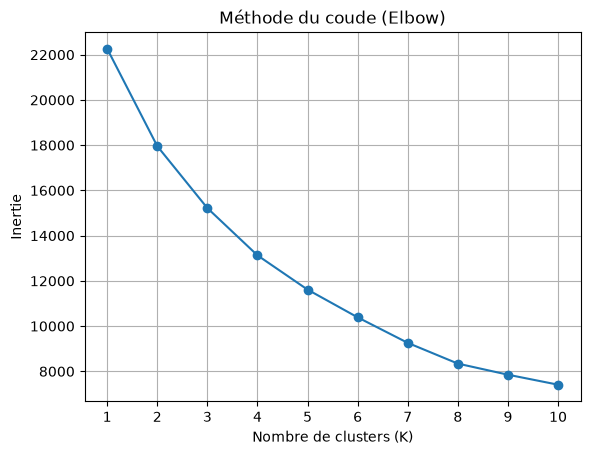

In [13]:
inerties = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_dataset)

    inerties.append(kmeans.inertia_)

# Tracer la courbe Elbow
plt.plot(range(1, 11), inerties, marker='o')
plt.xlabel("Nombre de clusters (K)")
plt.ylabel("Inertie")
plt.title("Méthode du coude (Elbow)")
plt.xticks(range(1, 11))
plt.grid()
plt.show()



d'apres la courbe on trouve que k=3

## 3.Application des algorithmes de clustering hiérarchique :

### 3.1 AGNES

**application de l algo**

In [43]:
Z = linkage(scaled_dataset, method='ward')

**Extraire les clusters**

In [16]:
clusters_agnes = fcluster(Z, t=3, criterion='maxclust')


print("\nNombre d'observations par cluster :")
print(pd.Series(clusters_agnes).value_counts().sort_index())


Nombre d'observations par cluster :
1     414
2      65
3    3232
Name: count, dtype: int64


### 3.2 DIANA 

In [18]:


# Créer le modèle DIANA
diana = Diana(n_clusters=3)

# Appliquer l'algorithme
diana.fit(scaled_dataset.to_numpy())

# Récupérer les clusters
clusters_diana = diana.labels_

# Afficher la répartition
print(pd.Series(clusters_diana).value_counts().sort_index())

0    3680
1      30
2       1
Name: count, dtype: int64


### 4 .DBSCAN.

 **MinPts**

In [21]:
n_features = scaled_dataset.shape[1]

min_pts = 2 * n_features
print("MinPts =", min_pts)

MinPts = 12


**EPS**

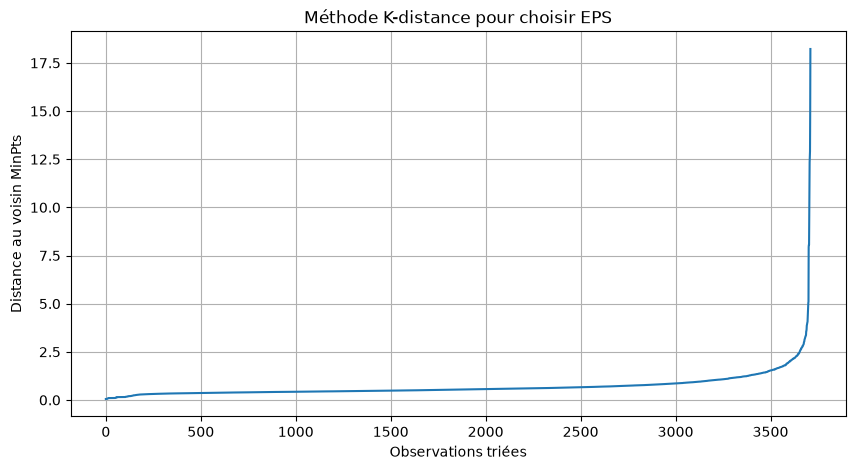

In [23]:
voisins = NearestNeighbors(n_neighbors=min_pts)
voisins.fit(scaled_dataset)

distances, indices = voisins.kneighbors(scaled_dataset)

distances_triees = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))
plt.plot(distances_triees)
plt.xlabel("Observations triées")
plt.ylabel("Distance au voisin MinPts")
plt.title("Méthode K-distance pour choisir EPS")
plt.grid()
plt.show()

ajustement les paramètres MinPts et EPS
pour obtenir le même nombre de clusters que celui trouvé avec la courbe
d'elbow.

In [ ]:


for min_pts in range(4, 21):       # MinPts de 4 a 20
    for eps in np.arange(0.1, 2.5, 0.1):  # EPS de 0.1 a 2.0

        dbscan = DBSCAN(eps=eps, min_samples=min_pts)
        labels = dbscan.fit_predict(scaled_dataset)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_bruit = np.sum(labels == -1)

        if n_clusters == 3:
            print(
                f"MinPts = {min_pts} | "
                f"EPS = {eps:.1f} | "
                f"Clusters = {n_clusters} | "
                f"Bruit = {n_bruit}"
            )

MinPts = 4 | EPS = 1.1 | Clusters = 3 | Bruit = 148
MinPts = 4 | EPS = 1.2 | Clusters = 3 | Bruit = 120
MinPts = 5 | EPS = 0.1 | Clusters = 3 | Bruit = 3580
MinPts = 5 | EPS = 0.5 | Clusters = 3 | Bruit = 967
MinPts = 5 | EPS = 0.6 | Clusters = 3 | Bruit = 675
MinPts = 5 | EPS = 0.8 | Clusters = 3 | Bruit = 365
MinPts = 5 | EPS = 1.3 | Clusters = 3 | Bruit = 113
MinPts = 6 | EPS = 0.5 | Clusters = 3 | Bruit = 1042
MinPts = 6 | EPS = 0.6 | Clusters = 3 | Bruit = 721
MinPts = 6 | EPS = 0.8 | Clusters = 3 | Bruit = 391
MinPts = 6 | EPS = 1.4 | Clusters = 3 | Bruit = 101
MinPts = 7 | EPS = 0.9 | Clusters = 3 | Bruit = 319
MinPts = 7 | EPS = 1.4 | Clusters = 3 | Bruit = 107
MinPts = 8 | EPS = 0.1 | Clusters = 3 | Bruit = 3591
MinPts = 8 | EPS = 1.4 | Clusters = 3 | Bruit = 110
MinPts = 10 | EPS = 0.1 | Clusters = 3 | Bruit = 3618
MinPts = 10 | EPS = 0.3 | Clusters = 3 | Bruit = 3226
MinPts = 10 | EPS = 0.5 | Clusters = 3 | Bruit = 1334
MinPts = 11 | EPS = 0.1 | Clusters = 3 | Bruit = 3634
M

**Remarque:** on va prendre minpts=6 et eps= 1.4 car avec ces valeurs on a trouvé k=3 et le min des points isolés (101)

**affichage des clusters**

In [31]:
dbscan = DBSCAN(eps=1.4, min_samples=6)
clusters_dbscan = dbscan.fit_predict(scaled_dataset)

print(pd.Series(clusters_dbscan).value_counts().sort_index())

-1     101
 0    3591
 1      15
 2       4
Name: count, dtype: int64


### 5. Évaluation des performances :

**affichage des clusters**

In [33]:

print("AGNES :", pd.Series(clusters_agnes).value_counts().sort_index())
print("\nDIANA :", pd.Series(clusters_diana).value_counts().sort_index())
print("\nDBSCAN :", pd.Series(clusters_dbscan).value_counts().sort_index())

AGNES : 1     414
2      65
3    3232
Name: count, dtype: int64

DIANA : 0    3680
1      30
2       1
Name: count, dtype: int64

DBSCAN : -1     101
 0    3591
 1      15
 2       4
Name: count, dtype: int64


**Calcul des métriques**

In [34]:


def evaluer_clustering(X, labels, nom):
    silhouette = silhouette_score(X, labels)
    davies = davies_bouldin_score(X, labels)
    calinski = calinski_harabasz_score(X, labels)

    print(f"\n{nom}")
    print(f"Silhouette Score : {silhouette:.4f}")
    print(f"Davies-Bouldin Index : {davies:.4f}")
    print(f"Calinski-Harabasz Index : {calinski:.4f}")


# AGNES
evaluer_clustering(scaled_dataset, clusters_agnes, "AGNES")

# DIANA
evaluer_clustering(scaled_dataset, clusters_diana, "DIANA")

# DBSCAN : exclusion des points bruit
masque = clusters_dbscan != -1

evaluer_clustering(
    scaled_dataset[masque],
    clusters_dbscan[masque],
    "DBSCAN"
)


AGNES
Silhouette Score : 0.4143
Davies-Bouldin Index : 1.2319
Calinski-Harabasz Index : 735.2405

DIANA
Silhouette Score : 0.7343
Davies-Bouldin Index : 0.5283
Calinski-Harabasz Index : 316.3933

DBSCAN
Silhouette Score : 0.5090
Davies-Bouldin Index : 0.7660
Calinski-Harabasz Index : 72.2132


**remarque:** Les résultats montrent que DIANA obtient le meilleur Silhouette Score (0.7343) et le meilleur Davies-Bouldin Index (0.5283), indiquant une bonne cohésion et une bonne séparation des clusters. AGNES présente le meilleur indice Calinski-Harabasz (735.2405). indiquant une bonne séparation des clusters par rapport à leur dispersion interne.

### 6. Comparaison des résultats :

premierement on doit appliquer kmeans et kmedoids 

In [40]:
# selon le graphique, le nombre optimal de clusters est 4
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(scaled_dataset)

# Ajouter les clusters aux donnees
clusters_kmeans = kmeans.labels_

# kmedoids

distances = euclidean_distances(scaled_dataset)

kmedoids_instance = kmedoids.KMedoids(
    n_clusters=3,
    method="fasterpam"
)

kmedoids_instance.fit(distances)
# Recuperer les clusters
clusters_kmedoids = kmedoids_instance.labels_


calcule des inerties 

In [41]:
def calculer_inertie(X, labels):
    inertie = 0

    for cluster in np.unique(labels):
        if cluster == -1:
            continue

        points = X[labels == cluster]
        centre = points.mean(axis=0)

        inertie += np.sum((points - centre) ** 2)

    return inertie


# Calcul des inerties
inerties = {
    "K-Means": calculer_inertie(scaled_dataset.to_numpy(), clusters_kmeans),
    "K-Medoids": calculer_inertie(scaled_dataset.to_numpy(), clusters_kmedoids),
    "AGNES": calculer_inertie(scaled_dataset.to_numpy(), clusters_agnes),
    "DIANA": calculer_inertie(scaled_dataset.to_numpy(), clusters_diana),
    "DBSCAN": calculer_inertie(scaled_dataset.to_numpy(), clusters_dbscan)
}

# Affichage des résultats
for methode, inertie in inerties.items():
    print(f"{methode} : {inertie:.2f}")



K-Means : 15219.01
K-Medoids : 15954.16
AGNES : 15943.35
DIANA : 19020.13
DBSCAN : 14204.25


histogramme de comparaison

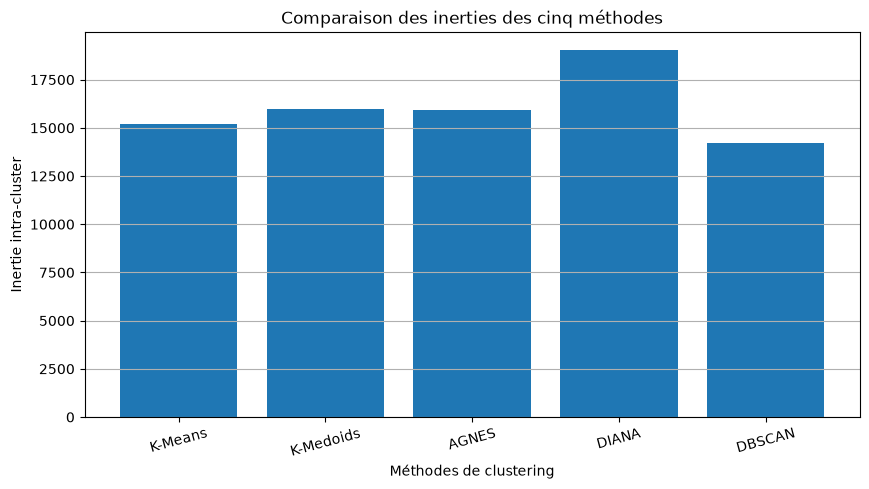

In [ ]:

plt.figure(figsize=(10, 5))
plt.bar(inerties.keys(), inerties.values())
plt.xlabel("Méthodes de clustering")
plt.ylabel("Inertie intra-cluster")
plt.title("Comparaison des inerties des cinq méthodes")
plt.xticks(rotation=15)
plt.grid(axis="y")
plt.show()

### Analyse comparative des performances des cinq méthodes


D'après l'histogramme, DBSCAN présente la plus faible inertie , suivi de K-Means. Cela indique une meilleure compacité des clusters obtenus selon cette mesure. En revanche, DIANA présente l'inertie la plus élevée.

Concernant les métriques d'évaluation :

- **DIANA** obtient le meilleur Silhouette Score (0.7343) et le meilleur Davies-Bouldin Index (0.5283), ce qui indique une bonne cohésion et une bonne séparation des clusters.
- **AGNES** obtient le meilleur indice Calinski-Harabasz (735.2405), indiquant une bonne séparation des clusters par rapport à leur dispersion interne.
- **DBSCAN** obtient un Silhouette Score de 0.5090 et un Davies-Bouldin Index de 0.7660. Cependant, deux de ses clusters contiennent très peu d'observations.
- **K-Means et K-Medoids** présentent des inerties relativement proches, K-Means ayant une inertie légèrement inférieure.

En conclusion, les résultats montrent que chaque méthode présente des avantages différents. DIANA se distingue selon les métriques Silhouette et Davies-Bouldin, AGNES selon Calinski-Harabasz, tandis que DBSCAN présente la plus faible inertie. 

Ainsi, aucune méthode ne peut être considérée comme la meilleure selon tous les critères : le choix dépend de l'objectif recherché